In [ ]:
'''
- Tree Based Algorithm
- Decision Tree
    - Tree Based Learning

- Random Forest
    - Tree Based and Ensemble Learning
    - Extension of Decision Tree
'''

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plot
import seaborn as sns

# Decision Tree
from sklearn.tree import DecisionTreeClassifier
# Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
df = pd.read_csv('Dataset/Fraud Detection Dataset.csv')
df

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,NaN,Mobile,NaN,3,115,9,NaN,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0
...,...,...,...,...,...,...,...,...,...,...,...,...
50995,T33982,2339,3112.51,Bill Payment,15.0,Mobile,New York,0,7,8,Debit Card,0
50996,T31261,2152,2897.15,Online Purchase,3.0,Mobile,Miami,1,75,11,Net Banking,1
50997,T12293,3345,2204.43,POS Payment,18.0,Mobile,San Francisco,3,73,5,Credit Card,0
50998,T42287,1518,4787.17,POS Payment,19.0,Tablet,New York,2,108,14,Net Banking,0


In [3]:
df.isnull().sum()

Transaction_ID                         0
User_ID                                0
Transaction_Amount                  2520
Transaction_Type                       0
Time_of_Transaction                 2552
Device_Used                         2473
Location                            2547
Previous_Fraudulent_Transactions       0
Account_Age                            0
Number_of_Transactions_Last_24H        0
Payment_Method                      2469
Fraudulent                             0
dtype: int64

In [4]:
## Remove duplicate data
df.drop_duplicates(subset='Transaction_ID', keep='first', inplace=True)

In [5]:
total_transaction = df['Transaction_ID'].count()
total_transaction

np.int64(50000)

In [6]:
non_Fraudulent = df[df['Fraudulent'] == 0]['Transaction_ID'].count()
non_Fraudulent

np.int64(47540)

In [7]:
yes_Fraudulent = df[df['Fraudulent'] == 1]['Transaction_ID'].count()
yes_Fraudulent

np.int64(2460)

In [8]:
df.fillna({
    'Transaction_Amount': df['Transaction_Amount'].median(),
    'Time_of_Transaction': df['Time_of_Transaction'].mode()[0]
}, inplace=True)

In [9]:
df.fillna({
    'Device_Used': 'Unknown Device',
    'Location': 'Unknown Location',
    'Payment_Method': 'Unknown Method'
}, inplace = True)

In [10]:
df.columns

Index(['Transaction_ID', 'User_ID', 'Transaction_Amount', 'Transaction_Type',
       'Time_of_Transaction', 'Device_Used', 'Location',
       'Previous_Fraudulent_Transactions', 'Account_Age',
       'Number_of_Transactions_Last_24H', 'Payment_Method', 'Fraudulent'],
      dtype='object')

In [11]:
columns = ['Transaction_Type', 'Device_Used', 'Location', 'Payment_Method']
le = LabelEncoder()

for col in columns:
    df[f'{col}_id'] = le.fit_transform(df[col])

## Features and Target

In [12]:
features = ['Transaction_Amount', 'Transaction_Type_id', 'Time_of_Transaction', 'Device_Used_id', 'Location_id',
           'Previous_Fraudulent_Transactions', 'Account_Age', 'Number_of_Transactions_Last_24H',
           'Payment_Method_id']
target = 'Fraudulent'

In [13]:
X = df[features]
Y = df[target]

## Train Test Split

In [14]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

## Feature Scaling

In [15]:
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

## Decision Tree

In [54]:
dt_model = DecisionTreeClassifier(
    max_depth=3, 
    random_state=42,
    class_weight='balanced'
)
dt_model.fit(X_train_scale, Y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


In [55]:
dt_pred = dt_model.predict(X_test_scale)

In [56]:
dt_cr = classification_report(Y_test, dt_pred)
dt_cm = confusion_matrix(Y_test, dt_pred)

In [57]:
print(dt_cr)

              precision    recall  f1-score   support

           0       0.95      0.72      0.82      9508
           1       0.05      0.26      0.08       492

    accuracy                           0.69     10000
   macro avg       0.50      0.49      0.45     10000
weighted avg       0.90      0.69      0.78     10000



In [58]:
print(dt_cm)

[[6818 2690]
 [ 365  127]]


<Axes: >

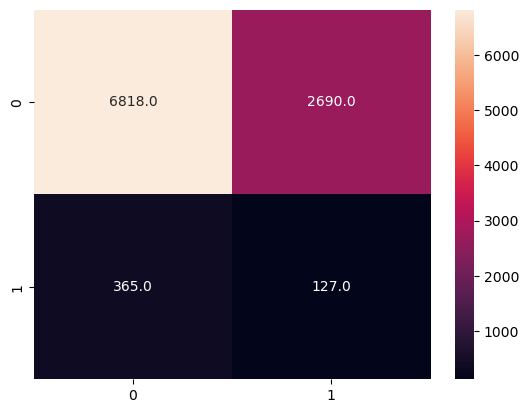

In [59]:
sns.heatmap(dt_cm, annot=True, fmt='1.1f')

## Random Forest Classifier

In [82]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight='balanced',
    max_depth=10,
    n_jobs=1
)
rf_model.fit(X_train_scale, Y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [83]:
rf_pred = rf_model.predict(X_test_scale)

In [84]:
rf_cm = confusion_matrix(Y_test, rf_pred)
rf_cr = classification_report(Y_test, rf_pred)

In [85]:
print(rf_cm)

[[9356  152]
 [ 486    6]]


In [86]:
print(rf_cr)

              precision    recall  f1-score   support

           0       0.95      0.98      0.97      9508
           1       0.04      0.01      0.02       492

    accuracy                           0.94     10000
   macro avg       0.49      0.50      0.49     10000
weighted avg       0.91      0.94      0.92     10000



<Axes: >

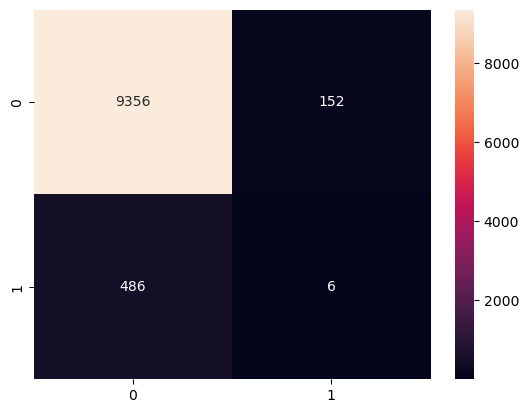

In [88]:
sns.heatmap(rf_cm, annot=True, fmt='1.0f')